# 01 · What do real returns look like?

Before generating anything synthetic, establish the target. These are the stylized facts from SCOPE.md, measured on real daily log returns for SPY, AAPL, JPM, XOM and JNJ. Each ticker is scaled by its own 2005–2019 standard deviation.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from src import config, data, metrics
ds = data.load_dataset(ROOT / "data" / "processed" / "windows.npz")

In [2]:
for name in ("train_eval", "test_eval"):
    print(name, ds[name].shape)
print({t: round(s, 5) for t, s in ds["scale"].items()})

train_eval (290, 64)
test_eval (95, 64)
{'SPY': 0.01155, 'AAPL': 0.02036, 'JPM': 0.0235, 'XOM': 0.01475, 'JNJ': 0.01016}


## A price path, and the returns that build it

SPY over the full period. The return series shows calm and violent stretches: that is volatility clustering, visible by eye.

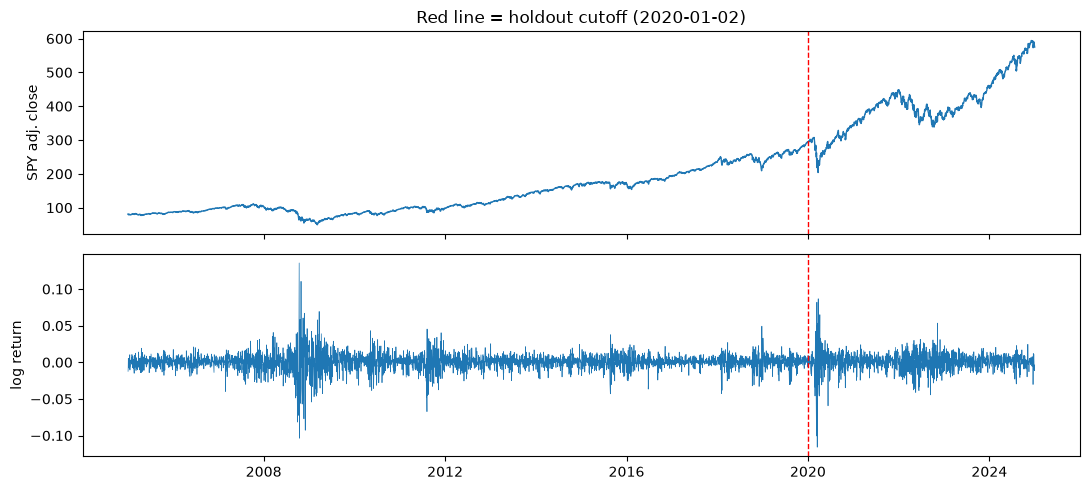

In [3]:
close = data.load_close("SPY")
r = data.log_returns(close)
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(close.index, close.values, lw=1); ax[0].set_ylabel("SPY adj. close")
ax[1].plot(r.index, r.values, lw=0.5); ax[1].set_ylabel("log return")
for a in ax: a.axvline(config.TEST_START, color="red", ls="--", lw=1)
ax[0].set_title("Red line = holdout cutoff (2020-01-02)")
plt.tight_layout()

## Fact 1 and 4: fat tails and skew

A normal distribution has excess kurtosis 0 and skew 0.

train_eval excess kurtosis  13.18   skew  -0.03
test_eval  excess kurtosis   8.45   skew  -0.20


Text(0.5, 1.0, 'Q-Q vs normal')

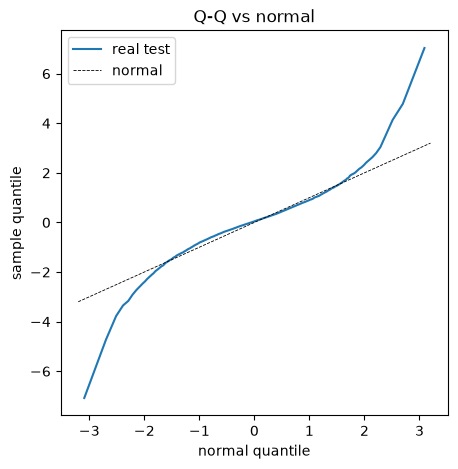

In [4]:
for name in ("train_eval", "test_eval"):
    x = ds[name].ravel()
    print(f"{name:10s} excess kurtosis {stats.kurtosis(x):6.2f}   skew {stats.skew(x):6.2f}")
x = ds["test_eval"].ravel()
q = np.linspace(0.001, 0.999, 400)
plt.figure(figsize=(5, 5))
plt.plot(stats.norm.ppf(q), np.quantile(x, q), lw=1.5, label="real test")
plt.plot([-3.2, 3.2], [-3.2, 3.2], "k--", lw=0.6, label="normal")
plt.xlabel("normal quantile"); plt.ylabel("sample quantile"); plt.legend(); plt.title("Q-Q vs normal")

## Fact 2 and 3: autocorrelation of r vs |r|

Raw returns are close to uncorrelated. Absolute returns are strongly and persistently correlated. ACFs pool lag products inside 64-day windows only.

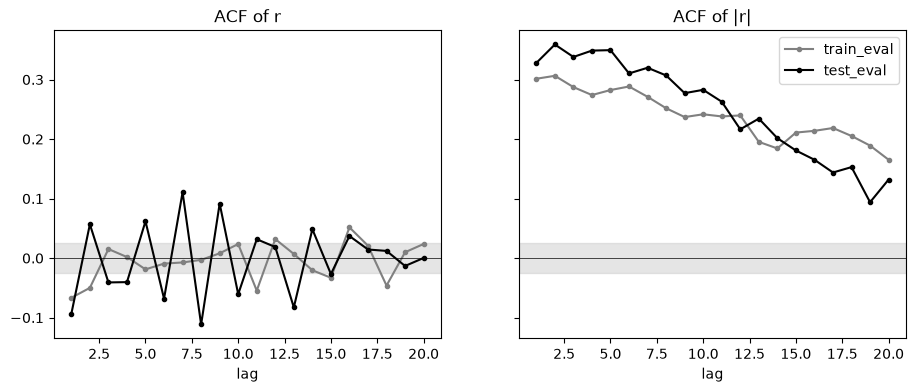

In [5]:
lags = np.arange(1, config.ACF_LAGS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for name, c in (("train_eval", "gray"), ("test_eval", "black")):
    ax[0].plot(lags, metrics.pooled_acf(ds[name]), "o-", ms=3, color=c, label=name)
    ax[1].plot(lags, metrics.pooled_acf(np.abs(ds[name])), "o-", ms=3, color=c, label=name)
band = 2 / np.sqrt(ds["test_eval"].size)
for a, t in zip(ax, ("ACF of r", "ACF of |r|")):
    a.axhspan(-band, band, color="#ccc", alpha=0.5); a.axhline(0, color="k", lw=0.5); a.set_title(t); a.set_xlabel("lag")
ax[1].legend()

## Takeaway

- **Fat tails:** strong in both periods.
- **Volatility clustering:** strong, decaying slowly over 20 lags. This is the fact GBM cannot produce.
- **Linear ACF:** small but not zero. Lag 1 is negative, outside the white-noise band.
- **Skew:** clearly negative only in the test period.

Notebook 02 asks how GBM and the diffusion model compare against this target.